In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report, roc_auc_score,roc_curve)
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"c:\Users\rampr\Downloads\archive.zip")


In [3]:
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [4]:
for i in df.select_dtypes(include=object).columns:
    print(df[i].unique())

<StringArray>
['I38PQUQS96', 'HPSK72WA7R', 'C1OZ6DPJ8Y', 'V2KKSFM3UN', 'EY08JDHTZP',
 'A9S62RQ7US', 'H8GXPAOS71', '0HGZQKJ36W', '1R0N3LGNRJ', 'CM9L1GTT2P',
 ...
 'DSL4O0KAWD', '6V8S5IUS63', 'O6SWO6CBGB', '48LOOK4VR1', 'AKXAXQN7PG',
 '8C6S86ESGC', '98R4KDHNND', 'XQK1UUUNGP', 'JAO28CPL4H', 'ZTH91CGL0B']
Length: 255347, dtype: str
<StringArray>
['Bachelor's', 'Master's', 'High School', 'PhD']
Length: 4, dtype: str
<StringArray>
['Full-time', 'Unemployed', 'Self-employed', 'Part-time']
Length: 4, dtype: str
<StringArray>
['Divorced', 'Married', 'Single']
Length: 3, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['Other', 'Auto', 'Business', 'Home', 'Education']
Length: 5, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [5]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [6]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
255342    False
255343    False
255344    False
255345    False
255346    False
Length: 255347, dtype: bool

<Axes: xlabel='Default'>

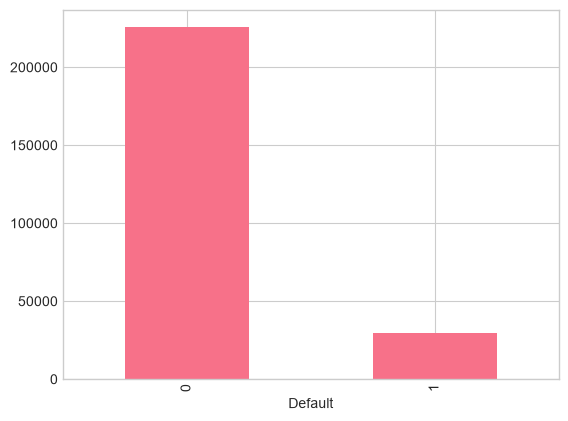

In [7]:
df['Default'].value_counts().plot(kind='bar')

In [8]:
df.select_dtypes(exclude='str').columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='str')

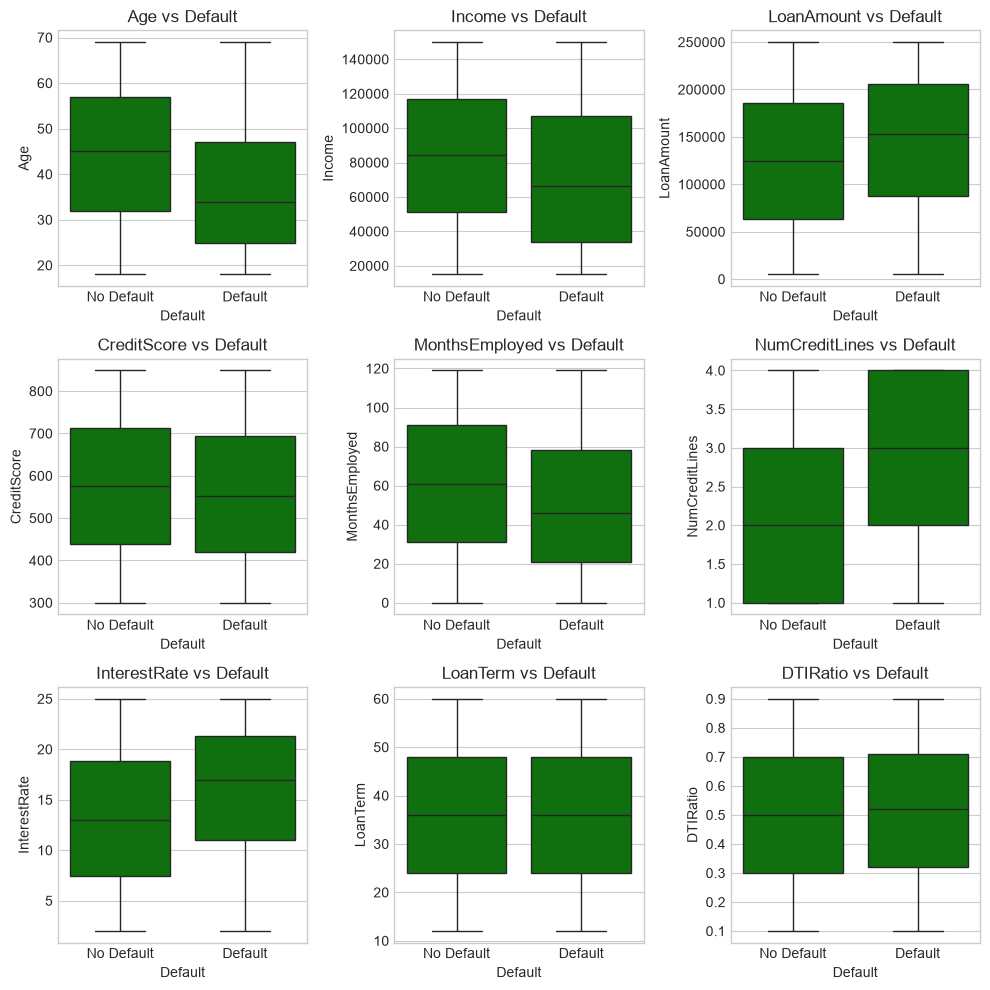

In [9]:
numerical_cols=['Age','Income','LoanAmount','CreditScore','MonthsEmployed', 'NumCreditLines','InterestRate','LoanTerm','DTIRatio']
fig, axs= plt.subplots(3,3,figsize=(10,10))
axs= axs.flatten()
for index,column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index], color='g')
    axs[index].set_title(f'{column_name} vs Default')
    axs[index].set_xticklabels(['No Default','Default'])
    plt.tight_layout()

In [10]:
#correlation

plt.figure(figsize=(10,8))
df[numerical_cols+['Default']].corr()


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000000,-0.001244,-0.002213,-0.000548,-0.000341,-0.000890,-0.001127,0.000263,-0.004689,-0.167783
Income,-0.001244,1.000000,-0.000865,-0.001430,0.002675,-0.002016,-0.002303,-0.000998,0.000205,-0.099119
LoanAmount,-0.002213,-0.000865,1.000000,0.001261,0.002817,0.000794,-0.002291,0.002538,0.001122,0.086659
CreditScore,-0.000548,-0.001430,0.001261,1.000000,0.000613,0.000016,0.000436,0.001130,-0.001039,-0.034166
MonthsEmployed,-0.000341,0.002675,0.002817,0.000613,1.000000,0.001267,0.000096,-0.001166,0.001765,-0.097374
NumCreditLines,-0.000890,-0.002016,0.000794,0.000016,0.001267,1.000000,-0.000297,-0.000226,-0.000586,0.028330
InterestRate,-0.001127,-0.002303,-0.002291,0.000436,0.000096,-0.000297,1.000000,0.000892,0.000575,0.131273
LoanTerm,0.000263,-0.000998,0.002538,0.001130,-0.001166,-0.000226,0.000892,1.000000,0.002273,0.000545
DTIRatio,-0.004689,0.000205,0.001122,-0.001039,0.001765,-0.000586,0.000575,0.002273,1.000000,0.019236
Default,-0.167783,-0.099119,0.086659,-0.034166,-0.097374,0.028330,0.131273,0.000545,0.019236,1.000000


<Figure size 1000x800 with 0 Axes>

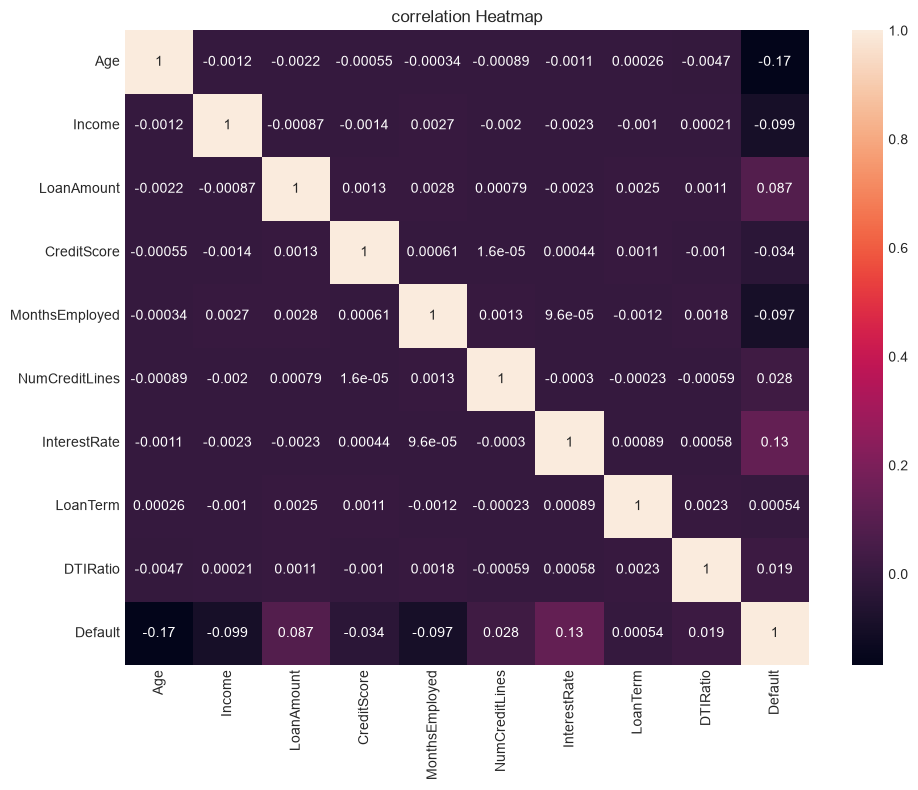

In [11]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr(),annot=True)
plt.title ('correlation Heatmap')
plt.tight_layout()
plt.show()

In [12]:
#data processing
df.drop ('LoanID',axis=1, inplace=True)


In [13]:
x= df.drop('Default',axis=1)
y= df['Default']

In [14]:

Categorical_column=x.select_dtypes(include='str').columns.to_list()
numerical_column=x.select_dtypes(exclude='str').columns.to_list()
label_encoders={}

for col in Categorical_column:
    le= LabelEncoder()
    x[col]=le.fit_transform(x[col].astype(str))
    print(f'encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}')

encoded Education: {"Bachelor's": np.int64(0), 'High School': np.int64(1), "Master's": np.int64(2), 'PhD': np.int64(3)}
encoded EmploymentType: {'Full-time': np.int64(0), 'Part-time': np.int64(1), 'Self-employed': np.int64(2), 'Unemployed': np.int64(3)}
encoded MaritalStatus: {'Divorced': np.int64(0), 'Married': np.int64(1), 'Single': np.int64(2)}
encoded HasMortgage: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded HasDependents: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded LoanPurpose: {'Auto': np.int64(0), 'Business': np.int64(1), 'Education': np.int64(2), 'Home': np.int64(3), 'Other': np.int64(4)}
encoded HasCoSigner: {'No': np.int64(0), 'Yes': np.int64(1)}


In [15]:
x

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1
1,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1
2,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0
3,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0
4,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,0,0,1,0,0,4,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,1,1,0,0,0,3,0
255344,56,84820,208294,597,70,3,5.29,60,0.50,1,2,1,1,1,0,1
255345,42,85109,60575,809,40,1,20.90,48,0.44,1,1,2,1,1,4,0


In [16]:

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=22
)

In [17]:
scaler=StandardScaler()
x_train_scaled=x_train.copy()
x_test_scaled= x_test.copy()

x_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_column])
x_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_column])

In [18]:
lr = LogisticRegression(class_weight='balanced',
max_iter=200,solver='lbfgs')
lr.fit(x_train_scaled,y_train)
y_pred=lr.predict(x_test_scaled)
y_pred_proba=lr.predict(x_test_scaled)
from sklearn.metrics import (ConfusionMatrixDisplay,confusion_matrix,
classification_report, accuracy_score, precision_score,recall_score,roc_curve,roc_auc_score)

In [19]:
print(f'accuracy_score: {accuracy_score(y_test,y_pred)}')
print(f'precision_score: {precision_score(y_test,y_pred)}')
print(f'recall_score: {recall_score(y_test,y_pred)}')
print(f'f1_score: {f1_score(y_test,y_pred_proba)}')
print(f'roc auc score: {roc_auc_score(y_test,y_pred_proba)}')

accuracy_score: 0.6735656941452908
precision_score: 0.2170673712021136
recall_score: 0.6890305266689031
f1_score: 0.33013219753284845
roc auc score: 0.6802761039835603


In [20]:
print(classification_report(y_test,y_pred,target_names=['No default','Default']))

              precision    recall  f1-score   support

  No default       0.94      0.67      0.78     45108
     Default       0.22      0.69      0.33      5962

    accuracy                           0.67     51070
   macro avg       0.58      0.68      0.56     51070
weighted avg       0.86      0.67      0.73     51070



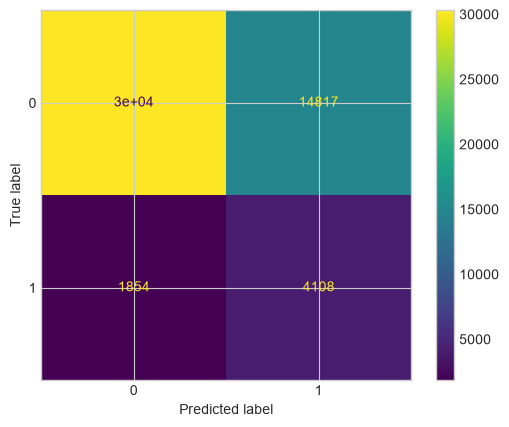

In [21]:
cm= confusion_matrix (y_test,y_pred)
dis = ConfusionMatrixDisplay(confusion_matrix=cm)
display_labels= ['No Default','Default']
dis.plot()
plt.show()


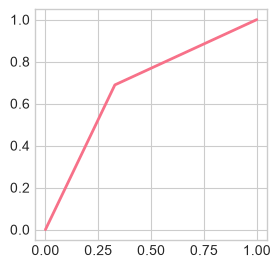

In [22]:
fpr, tpr , thresholds= roc_curve(y_test,y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr, tpr, lw=2)

In [23]:
import pandas as pd

In [24]:
coef_df= pd.DataFrame({
    'Columns':x_train.columns,
    'cofficient':lr.coef_[0]
    }).sort_values(by='cofficient', key=abs,ascending=False)

In [25]:
coef_df

,Columns,cofficient
0,Age,-0.590948
6,InterestRate,0.458811
4,MonthsEmployed,-0.340088
1,Income,-0.311435
2,LoanAmount,0.285226
15,HasCoSigner,-0.262539
13,HasDependents,-0.238367
12,HasMortgage,-0.156919
10,EmploymentType,0.127914
3,CreditScore,-0.121901


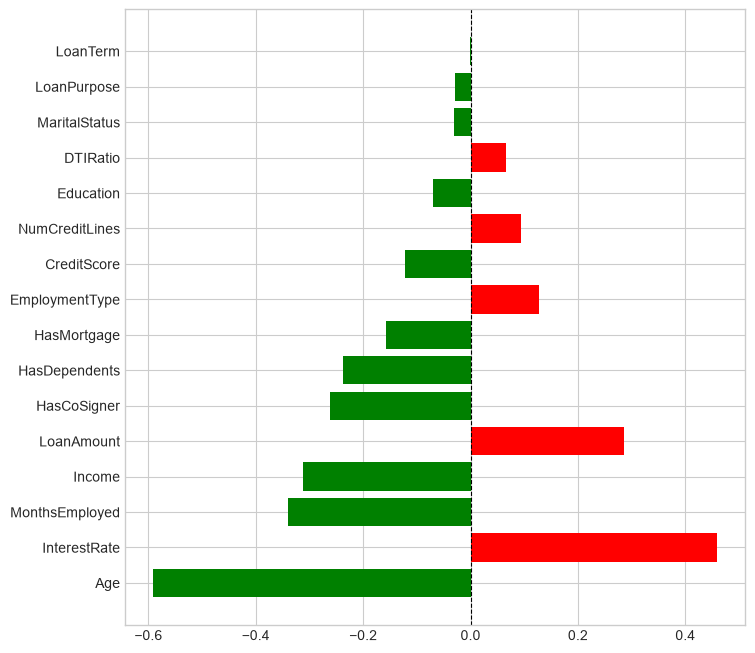

In [26]:
plt.figure(figsize=(8,8))
color=['r' if c>0 else 'g' for c  in coef_df['cofficient']]
plt.barh(coef_df['Columns'], coef_df['cofficient'],color=color)
plt.axvline(x=0 , color='black', linewidth=0.8, linestyle='--')
plt.show()

In [32]:
x_test.iloc[:2,:].ndim

2

In [33]:
import joblib
joblib.dump(lr,'logistic_regression.pkl')

['logistic_regression.pkl']

In [34]:
model=joblib.load('logistic_regression.pkl')

In [35]:
model.predict(x_test.iloc[:2,:])

array([1, 1])